# Luma - Lokalny Urok Mistrzostwa Artytycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

## Import bibliotek

In [1]:
import numpy as np
import pandas as pd
from itertools import chain
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## Wygenerowanie syntetycznych danych

### Ustawienie ziarna RNG

In [2]:
RNG_SEED = 20251021
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20251021


### Zdefiniowanie "stałych"

In [3]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [4]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 160, 80, 160, 150, 70, 90, 110], #średni popyt lokalny (szt./tydz.)
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], #średni popyt turystyczny (szt./tydz.)
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135] #średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy: (lokalni + turysći) * cena

In [5]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

In [6]:
display(catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,160,80,150,36000
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


## Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)

In [7]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    return df[["category", "demand_loc", "demand_tur"]]

### Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [8]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]

### Generowanie danych tygodniowych

In [9]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

## Wygenerowanie danych tygodniowych

In [10]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,944,448,1392,8
1,Tekstylia,25320,5880,31200,120
2,Biżuteria,28050,10650,38700,150
3,Rękodzieło,23000,6900,29900,230
4,Przetwory,5000,2840,7840,40
5,Dekoracje,5145,1050,6195,35
6,Stolarka,14250,9750,24000,250
7,Masarstwo,19995,8385,28380,215
8,Alkohole,17415,11205,28620,135


Łączny przychód w tygodniu 1 (PLN):  196227


## Analiza i wizualizacja danych

### Podstawowe wykresy

<Axes: >

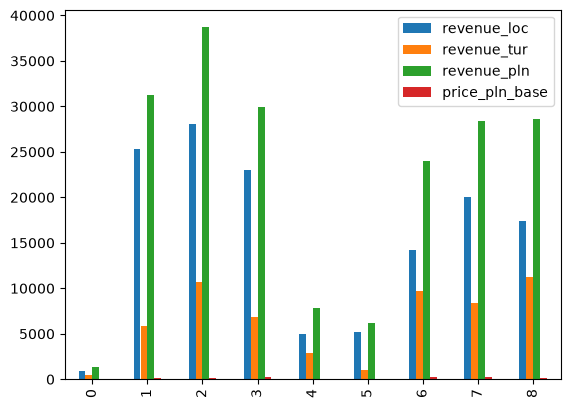

In [11]:
t1.plot.bar()

<Axes: >

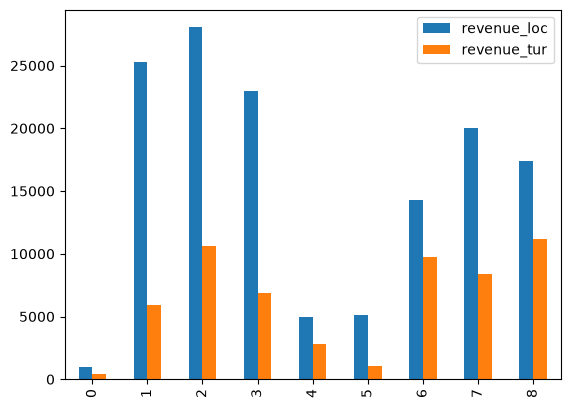

In [12]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

<Axes: >

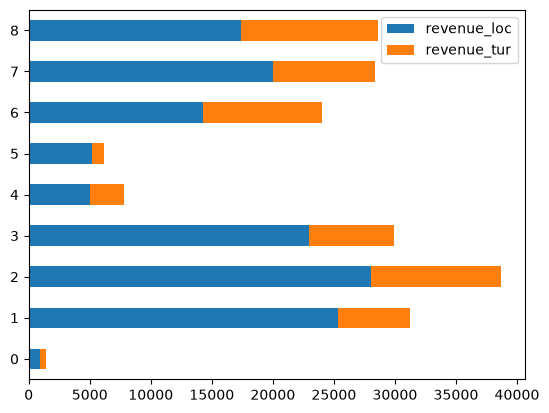

In [13]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

### Minimalny wykres

<BarContainer object of 9 artists>

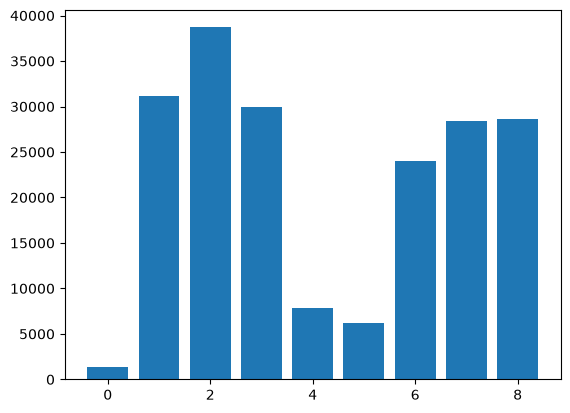

In [14]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

### Jawne tworzenie i wyświetlanie wykresu

In [15]:
heights = t1["revenue_pln"]
categories = t1["category"]

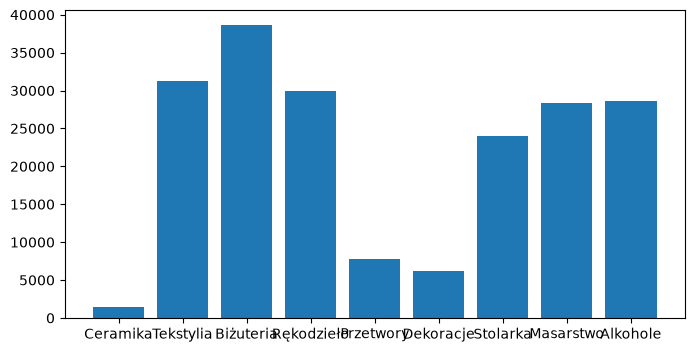

In [16]:
plt.figure(figsize=(8, 4))
plt.bar(categories, heights)
plt.show()

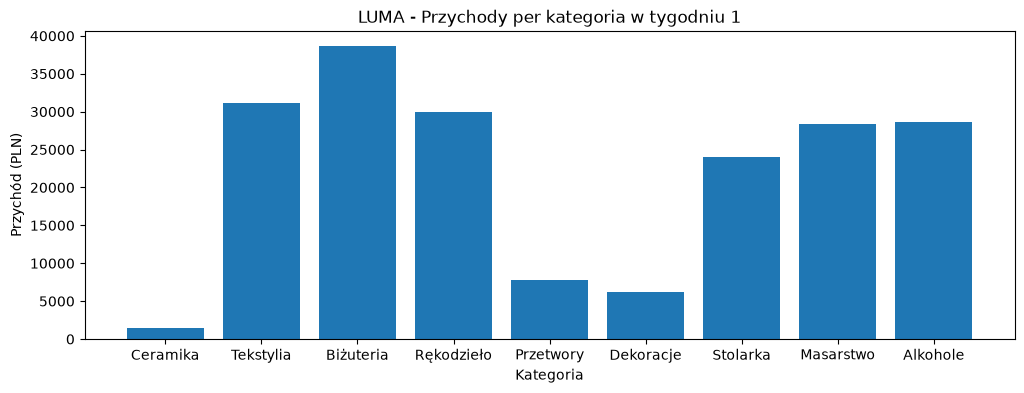

In [17]:
plt.figure(figsize=(12, 4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

### Etykiety wartości i formatowanie liczb

In [18]:
def format_pln(value: float) -> str:
    return f"{int(round(value)):_} zł".replace("_", "\u202f")

In [19]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim() 
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax + pad)

In [20]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha='center', va='bottom')

In [21]:
def format_tys(x: float, decimals: int = 0) -> str:
    v = x / 1000
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",", "\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",", "\u202f").replace(".", ",")
    return f"{s} tys."

In [22]:
def format_mln(x: float, decimals: int = 0) -> str:
    v = x / 1000000
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",", "\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",", "\u202f").replace(".", ",")
    return f"{s} mln."

In [23]:
print(format_tys(123456789))
print(format_tys(123))
print(format_mln(123456789))

123 457 tys.
0 tys.
123 mln.


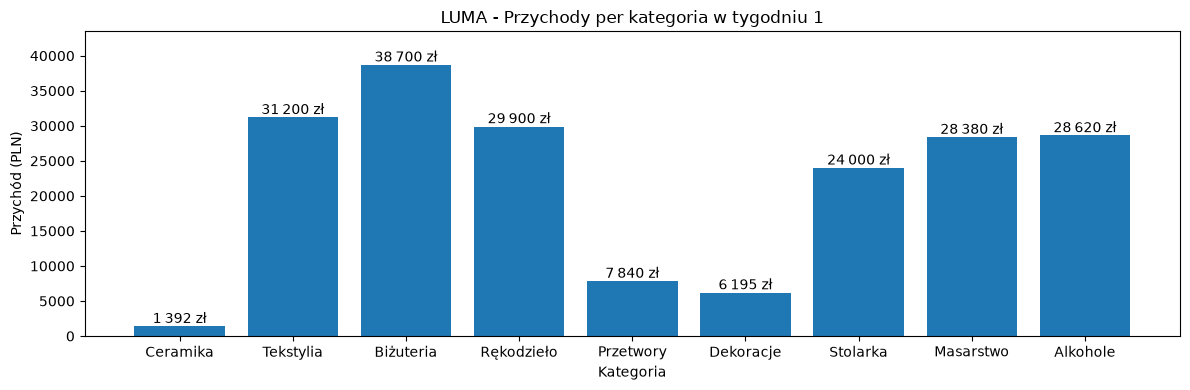

In [24]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis(factor=0.07)
label_bars_pln(bars)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

### Formatowanie etykiet podziałki osi

In [25]:
def format_y_ticks_tys():
    ticks, _ = plt.yticks()
    plt.yticks(ticks, [format_tys(value) for value in ticks])

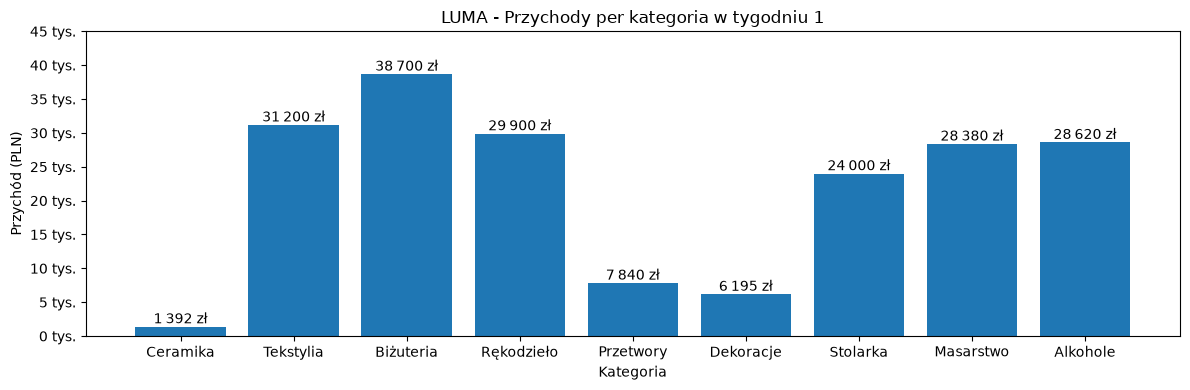

In [26]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_y_ticks_tys()
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

### Sortowanie kategorii dla łatwiejszego porównania

In [27]:
t1_sorted = t1.sort_values("revenue_pln", ascending=False)
categories_sorted = t1_sorted["category"]
heights_sorted = t1_sorted["revenue_pln"]

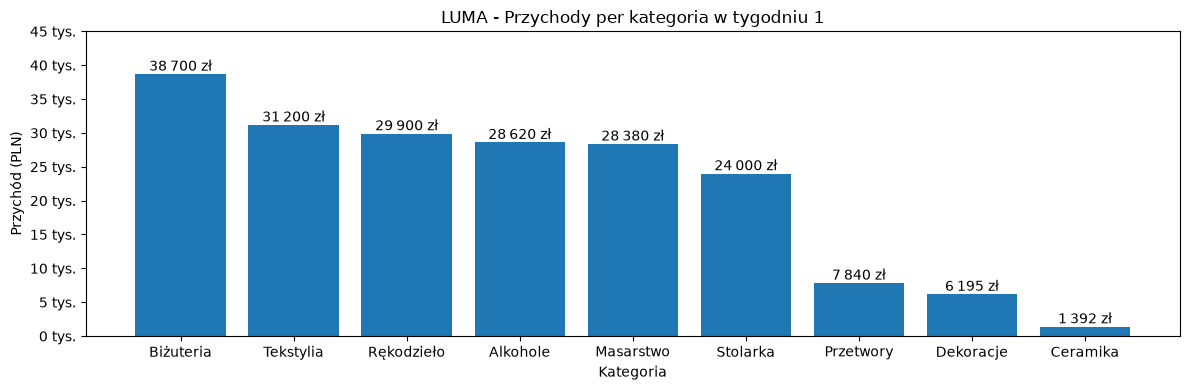

In [28]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories_sorted, heights_sorted)
pad_axis()
label_bars_pln(bars)
format_y_ticks_tys()
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

### Siatka w tle wykresu

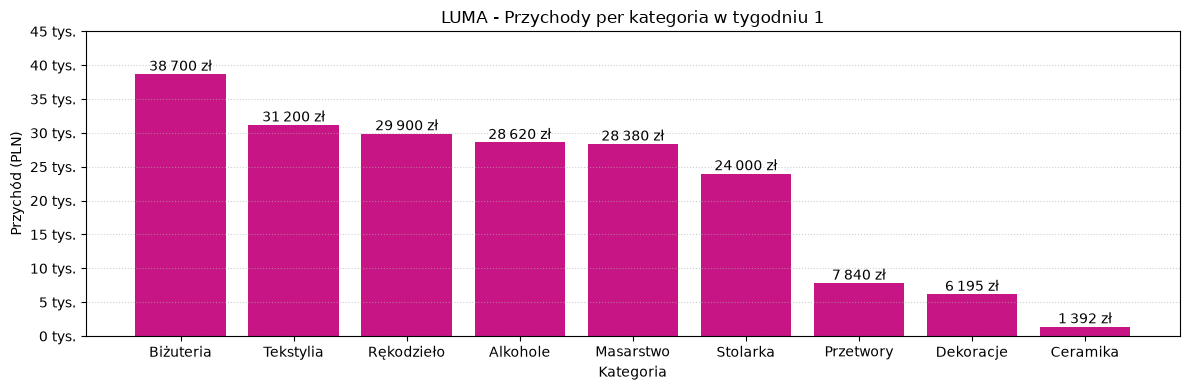

In [29]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories_sorted, heights_sorted, color="mediumvioletred")
pad_axis()
label_bars_pln(bars)
format_y_ticks_tys()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - 2 serie danych

### Wygenerowanie danych tygodniowych dla Tygodnia 2

Mini-festiwal przyciąga klientów: lokalni +13%, turyści +20%

In [30]:
boost_loc = 0.13
boost_tur = 0.20

t2 = generate_weekly_data(catalog, rng, boost_loc=boost_loc, boost_tur=boost_tur)
t2 = t2.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 2 - przychody per kategoria (PLN)")
display(t2)
print("Łączny przychód w tygodniu 1: ", format_pln(t1["revenue_pln"].sum()))
print("Łączny przychód w tygodniu 2: ", format_pln(t2["revenue_pln"].sum()))

Tydzień 2 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,1080,536,1616,8
1,Tekstylia,28200,6960,35160,120
2,Biżuteria,22650,16350,39000,150
3,Rękodzieło,18400,8050,26450,230
4,Przetwory,6720,5200,11920,40
5,Dekoracje,4655,980,5635,35
6,Stolarka,21500,14500,36000,250
7,Masarstwo,25155,10965,36120,215
8,Alkohole,15120,13500,28620,135


Łączny przychód w tygodniu 1:  196 227 zł
Łączny przychód w tygodniu 2:  220 521 zł


Przygotowanie danych do wykresów

In [31]:
categories_sorted = t1_sorted["category"]
t1_revenue_total = t1_sorted["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[categories_sorted]["revenue_pln"]
x_locs = np.arange(len(categories_sorted))
bar_width = 0.4
bar_half = bar_width / 2

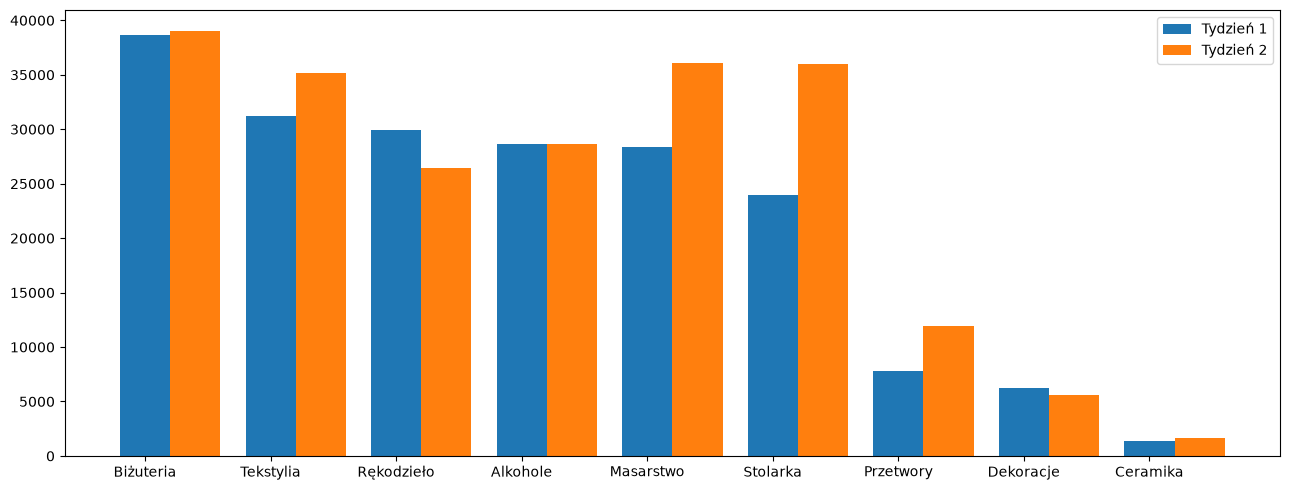

In [32]:
plt.figure(figsize=(13,5))
plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, 
        label="Tydzień 1", tick_label=categories_sorted)
plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, 
        label="Tydzień 2")
plt.legend()
plt.tight_layout()
plt.show()


Łączne operowanie na seriach

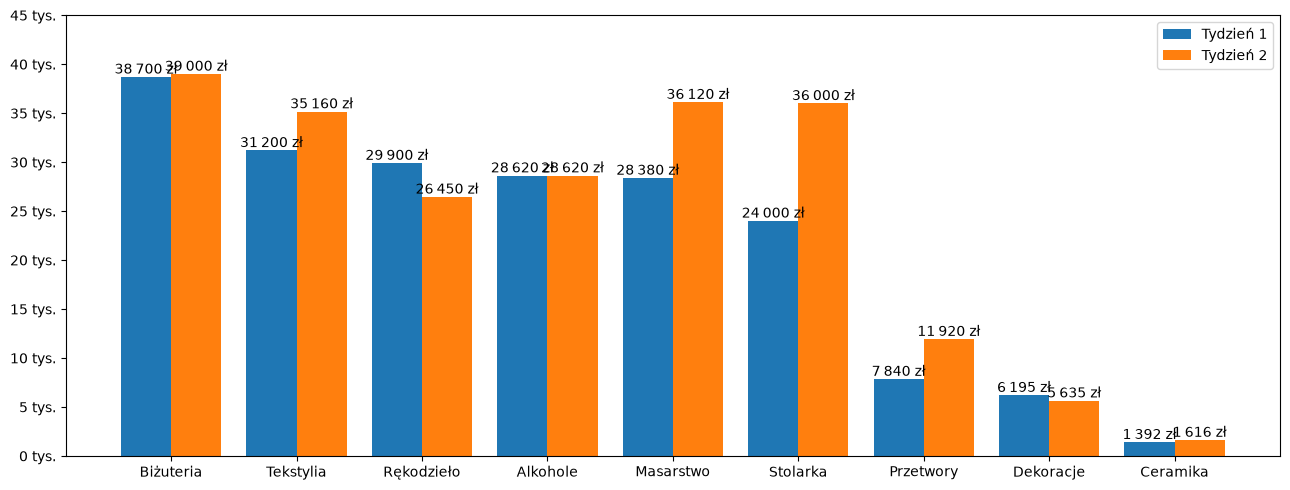

In [33]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1")
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2")
plt.xticks(x_locs, categories_sorted)
pad_axis()
label_bars_pln(chain(bars_1, bars_2))
format_y_ticks_tys()

plt.legend()
plt.tight_layout()
plt.show()

Aktualizacja wyświetlania etykiet wartości

In [34]:
def format_sep(x: float) -> str:
    return f"{int(round(x)):,}".replace(",", "\u202f")

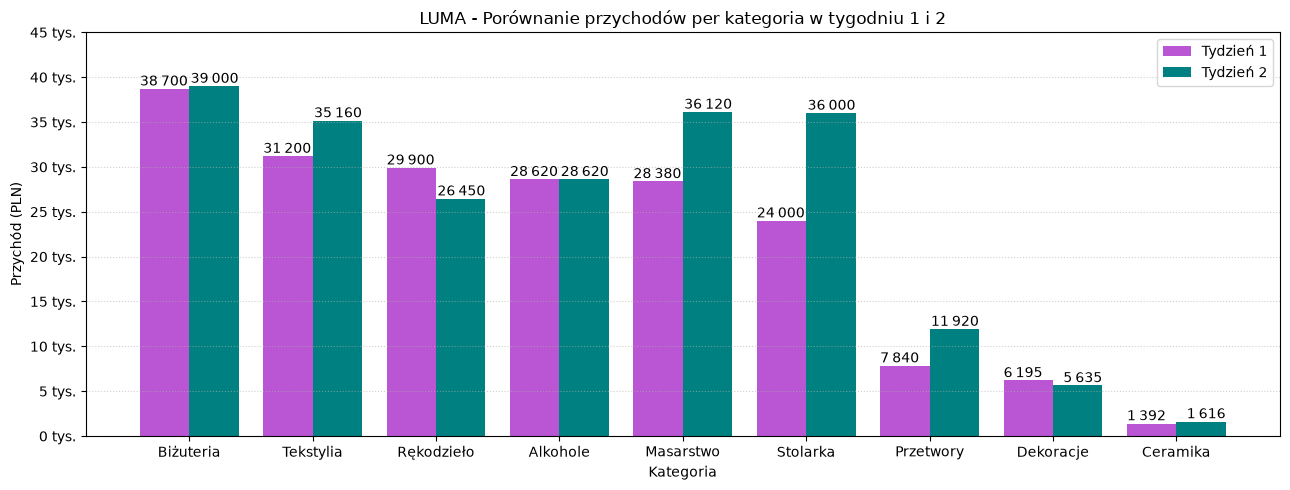

In [35]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1", color="mediumorchid")
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2", color="teal")
plt.xticks(x_locs, categories_sorted)
pad_axis()
for b in bars_1:
    x, y = b.get_x(), b.get_height()
    plt.text(x, y, format_sep(y), ha="left", va="bottom")
for b in bars_2:
    x, y = b.get_x() + b.get_width(), b.get_height()
    plt.text(x, y, format_sep(y), ha="right", va="bottom")
format_y_ticks_tys()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Porównanie przychodów per kategoria w tygodniu 1 i 2")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.legend()
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - prezentacja zmian bezwzględnych

Zmiana bezwzględna to przychód z tygodnia 2 minus przychód z tygodnia 1. Tabela pokazuje wartości w PLN i zmianę procentową; kolejne wykresy skupiają się na zmianie bezwzględnej.

In [36]:
order = CATEGORIES
t1_by_category = t1.set_index("category").loc[order, "revenue_pln"].to_numpy()
t2_by_category = t2.set_index("category").loc[order, "revenue_pln"].to_numpy()
delta = t2_by_category - t1_by_category

pct = np.divide(
    delta,
    t1_by_category,
    out=np.full(t1_by_category.shape, np.nan, dtype=float),
    where=t1_by_category != 0,
) * 100

t_delta = pd.DataFrame({
    "category": order,
    "t1_pln": t1_by_category.astype(int),
    "t2_pln": t2_by_category.astype(int),
    "delta_pln": delta.astype(int),
    "delta_pct": np.round(pct, 1),
})

display(t_delta)

,category,t1_pln,t2_pln,delta_pln,delta_pct
0,Ceramika,1392,1616,224,16.1
1,Tekstylia,31200,35160,3960,12.7
2,Biżuteria,38700,39000,300,0.8
3,Rękodzieło,29900,26450,-3450,-11.5
4,Przetwory,7840,11920,4080,52.0
5,Dekoracje,6195,5635,-560,-9.0
6,Stolarka,24000,36000,12000,50.0
7,Masarstwo,28380,36120,7740,27.3
8,Alkohole,28620,28620,0,0.0


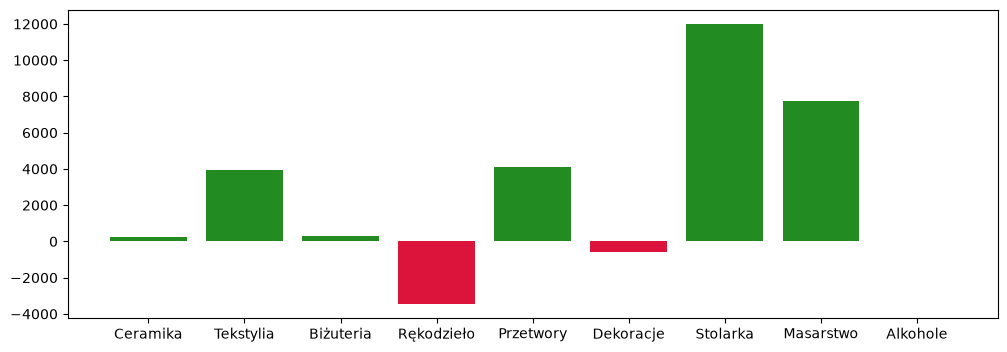

In [37]:
colors = ["forestgreen" if value >= 0 else "crimson" for value in t_delta["delta_pln"]]
plt.figure(figsize=(12, 4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
plt.show()

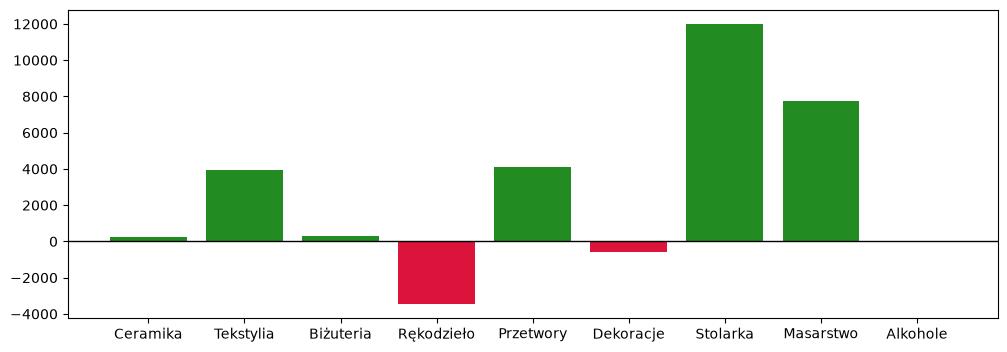

In [38]:
plt.figure(figsize=(12, 4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.show()

In [39]:
def format_sep_signed(x: float) -> str:
    sign = "+" if x >= 0 else "\u2212"
    return f"{sign}{format_sep(abs(x))}"

In [40]:
def pad_ylims(axes, factor=0.07):
    ymin, ymax = axes.get_ylim()
    padding = (ymax - ymin) * factor
    axes.set_ylim(ymin - padding, ymax + padding)

In [41]:
def label_bars(axes, bars, values, formatter=format_sep_signed, offset_factor=0.02):
    ymin, ymax = axes.get_ylim()
    offset = (ymax - ymin) * offset_factor

    for bar, value in zip(bars, values):
        y = bar.get_y() + bar.get_height()
        negative = value < 0
        axes.text(
            bar.get_x() + bar.get_width() / 2,
            y - offset if negative else y + offset,
            formatter(value),
            ha="center",
            va="top" if negative else "bottom",
        )

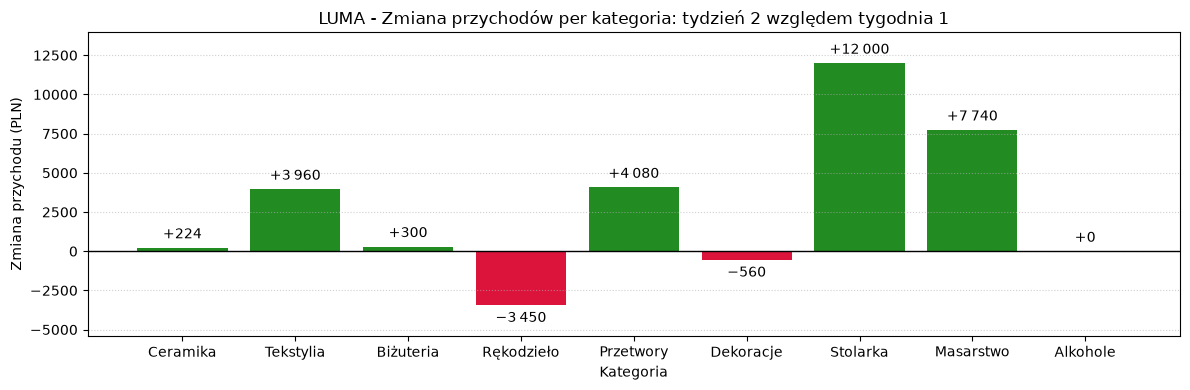

In [42]:
plt.figure(figsize=(12, 4))
ax = plt.gca()
bars = ax.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
pad_ylims(ax)
label_bars(ax, bars, t_delta["delta_pln"])
ax.axhline(0, color="black", linewidth=1)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.set_title("LUMA - Zmiana przychodów per kategoria: tydzień 2 względem tygodnia 1")
ax.set_xlabel("Kategoria")
ax.set_ylabel("Zmiana przychodu (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - prezentacja zmian względnych (procentowych)

In [43]:
increase_color = "#087E83"
decrease_color = "#9E327F"
neutral_color = "#64748B"

t_delta["delta_pct_plot"] = t_delta["delta_pct"]

In [44]:
def format_pct_signed(p: float) -> str:
    if np.isnan(p):
        return "n/a"
    if p == 0:
        return "0"
    s = f"{abs(p):.1f}".removesuffix(".0").replace(".", ",")
    return ("+" if p>=0 else "\u2212") + s + " %"

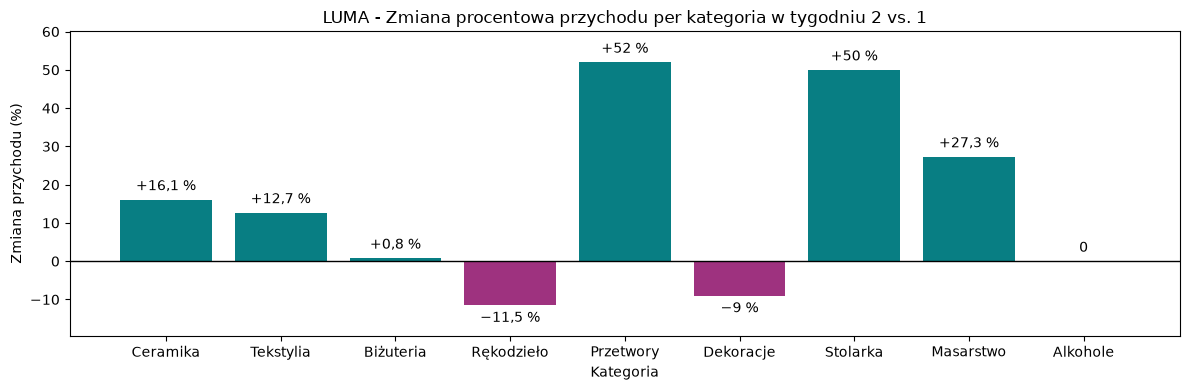

In [45]:
colors_pct = [increase_color if p > 0 else decrease_color if p<0 else neutral_color for p in t_delta['delta_pct_plot']]
plt.figure(figsize=(12,4))
bars = plt.bar(t_delta["category"], t_delta["delta_pct_plot"].fillna(0), color=colors_pct)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pct_plot"], formatter=format_pct_signed)
plt.axhline(0, color="black", linewidth=1)
plt.title("LUMA - Zmiana procentowa przychodu per kategoria w tygodniu 2 vs. 1")
plt.xlabel("Kategoria")
plt.ylabel("Zmiana przychodu (%)")
plt.tight_layout()
plt.show()

In [46]:
t_delta["delta_pct_plot"] = t_delta["delta_pct"].mask(t_delta["delta_pct"].abs() < 1, 0)

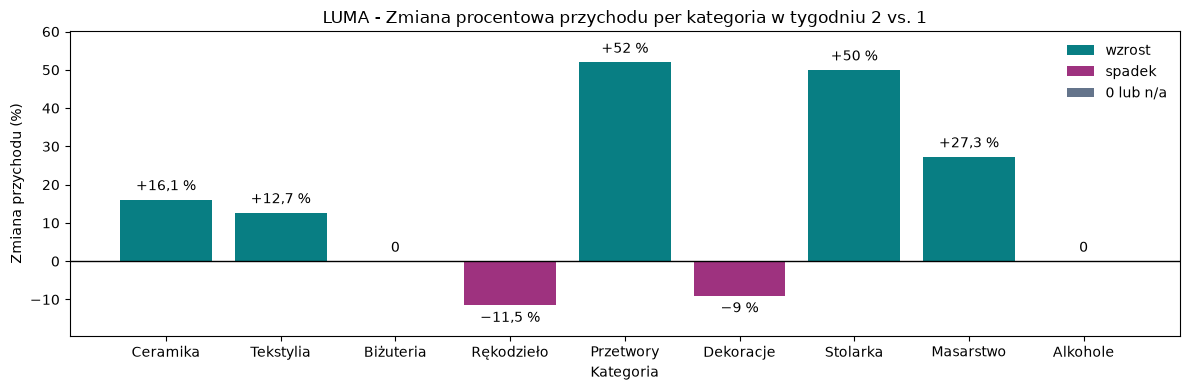

In [47]:
colors_pct = [increase_color if p > 0 else decrease_color if p<0 else neutral_color for p in t_delta['delta_pct_plot']]
plt.figure(figsize=(12,4))
bars = plt.bar(t_delta["category"], t_delta["delta_pct_plot"].fillna(0), color=colors_pct)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pct_plot"], formatter=format_pct_signed)
legend_patches = [
    Patch(facecolor=increase_color, label="wzrost"),
    Patch(facecolor=decrease_color, label="spadek"),
    Patch(facecolor=neutral_color, label="0 lub n/a")
]
plt.legend(handles=legend_patches, frameon=False)
plt.axhline(0, color="black", linewidth=1)
plt.title("LUMA - Zmiana procentowa przychodu per kategoria w tygodniu 2 vs. 1")
plt.xlabel("Kategoria")
plt.ylabel("Zmiana przychodu (%)")
plt.tight_layout()
plt.show()

Indywidualna modyfikacja słupków. Zmiany poniżej 1% są oznaczane jak zero. Wartości nieobliczalne mają etykietę „n/a”.

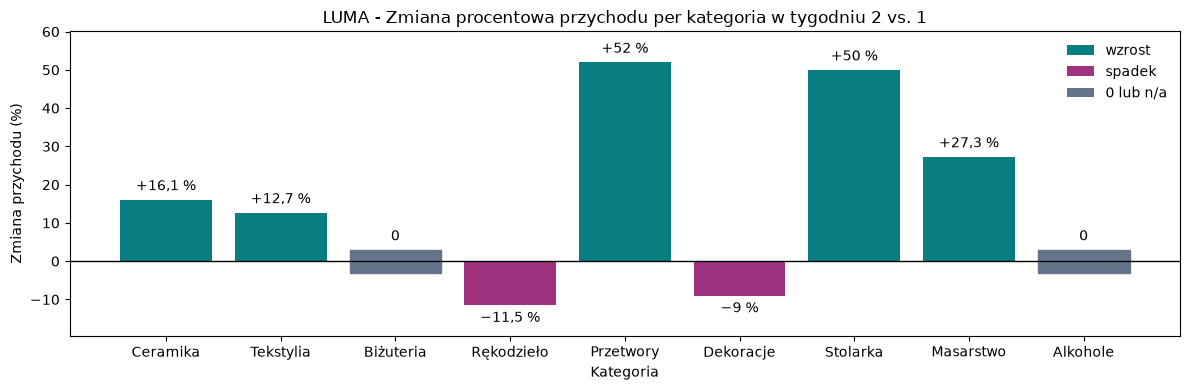

In [48]:
plt.figure(figsize=(12,4))
bars = plt.bar(t_delta["category"], t_delta["delta_pct_plot"].fillna(0), color=colors_pct)
for b, p in zip(bars, t_delta["delta_pct_plot"]):
    if np.isnan(p) or p == 0:
        b.set_y(-3)
        b.set_height(6)
        b.set_color(neutral_color)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pct_plot"], formatter=format_pct_signed)
legend_patches = [
    Patch(facecolor=increase_color, label="wzrost"),
    Patch(facecolor=decrease_color, label="spadek"),
    Patch(facecolor=neutral_color, label="0 lub n/a")
]
plt.legend(handles=legend_patches, frameon=False)
plt.axhline(0, color="black", linewidth=1)
plt.title("LUMA - Zmiana procentowa przychodu per kategoria w tygodniu 2 vs. 1")
plt.xlabel("Kategoria")
plt.ylabel("Zmiana przychodu (%)")
plt.tight_layout()
plt.show()

In [49]:
def modify_zero_bars(bars, values, **kwargs):
    for b, v in zip(bars, values):
        if np.isnan(v) or v == 0:
            b.set(**kwargs)

In [50]:
def add_manual_legend(*kwarg):
    legend_patches = [Patch(**k) for k in kwarg]
    plt.legend(handles=legend_patches)

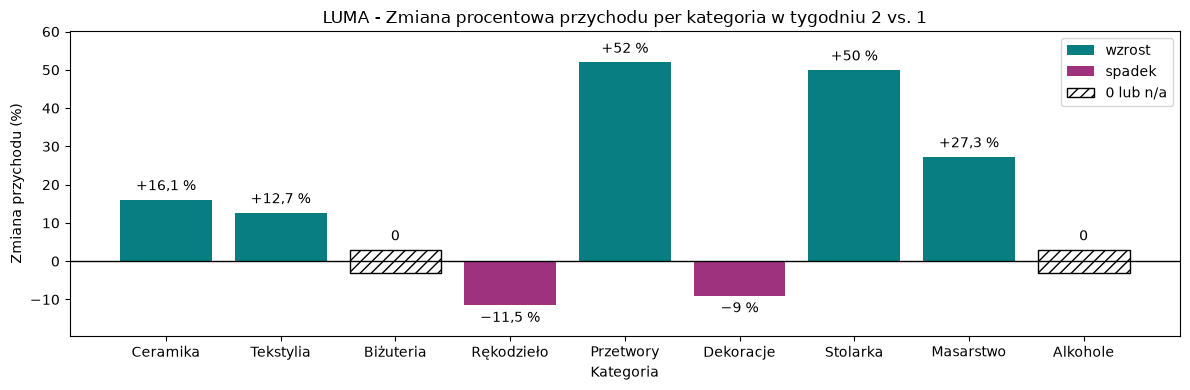

In [51]:
plt.figure(figsize=(12,4))
bars = plt.bar(t_delta["category"], t_delta["delta_pct_plot"].fillna(0), color=colors_pct)
modify_zero_bars(bars, t_delta["delta_pct_plot"], y=-3, height=6, hatch="///", facecolor="none", edgecolor="black")
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pct_plot"], formatter=format_pct_signed)
add_manual_legend(
    {"facecolor":increase_color, "label":"wzrost"},
    {"facecolor":decrease_color, "label":"spadek"},
    {"facecolor":"none", "label":"0 lub n/a", "hatch":"///", "edgecolor":"black"}
)
plt.axhline(0, color="black", linewidth=1)
plt.title("LUMA - Zmiana procentowa przychodu per kategoria w tygodniu 2 vs. 1")
plt.xlabel("Kategoria")
plt.ylabel("Zmiana przychodu (%)")
plt.tight_layout()
plt.show()

## Zmiany względne i bezwzględne na jednym wykresie

Pomocnicze współrzędne poziome słupków

In [52]:
x_locs = np.arange(len(order))
bar_width = 0.45
bar_half = bar_width / 2

colors_pln = [increase_color if value > 0 else decrease_color if value < 0 else neutral_color
              for value in t_delta["delta_pln"]]

Praca z dwoma układami współrzędnych

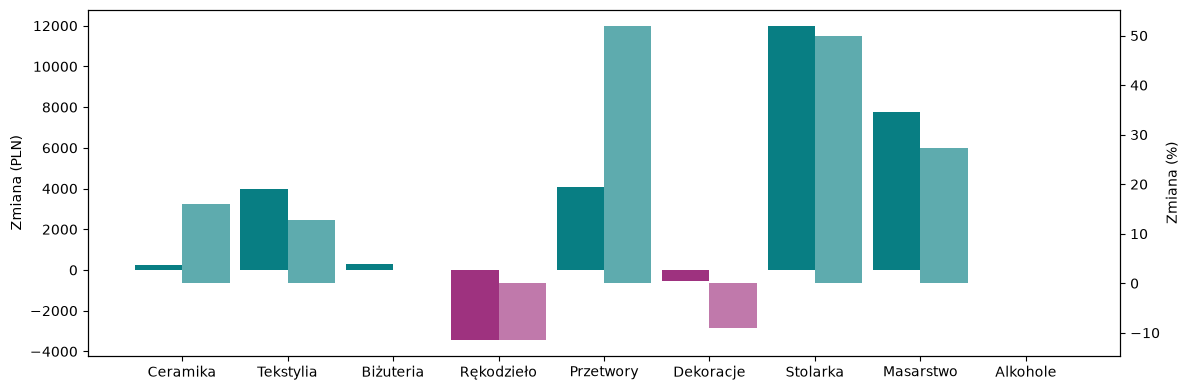

In [53]:
fig = plt.figure(figsize=(12,4))
ax_pln = plt.gca()
ax_pct = ax_pln.twinx()
bars_pln = ax_pln.bar(x_locs-bar_half, t_delta["delta_pln"], width=bar_width, color=colors_pln)
bars_pct = ax_pct.bar(x_locs+bar_half, t_delta["delta_pct_plot"].fillna(0), width=bar_width, color=colors_pct, alpha=0.65)
ax_pln.set_xticks(x_locs, order)
ax_pln.set_ylabel("Zmiana (PLN)")
ax_pct.set_ylabel("Zmiana (%)")
plt.tight_layout()
plt.show()

In [54]:
def align_value_expand(ax_ref, v_ref, ax_other, v_other, eps=1e-12):
    r0, r1 = ax_ref.get_ylim()
    if r0 == r1:
        return
    f = (v_ref - r0) / (r1 - r0)

    y0, y1 = ax_other.get_ylim()
    inv = y1 < y0
    a0, a1 = (y1, y0) if inv else (y0, y1)
    if a1 == a0:
        return
    if inv:
        f = 1 - f
    g = (v_other - a0) / (a1 - a0)
    f = min(max(f, eps), 1-eps)

    if g < f - eps:
        a0p = (v_other - f * a1) / (1 - f)
        a0_new, a1_new = min(a0, a0p), a1
    elif g > f + eps:
        a1p = (v_other - (1 - f) * a0) / f
        a0_new, a1_new = a0, max(a1, a1p)
    else:
        a0_new, a1_new = a0, a1
    ax_other.set_ylim((a1_new, a0_new) if inv else (a0_new, a1_new))

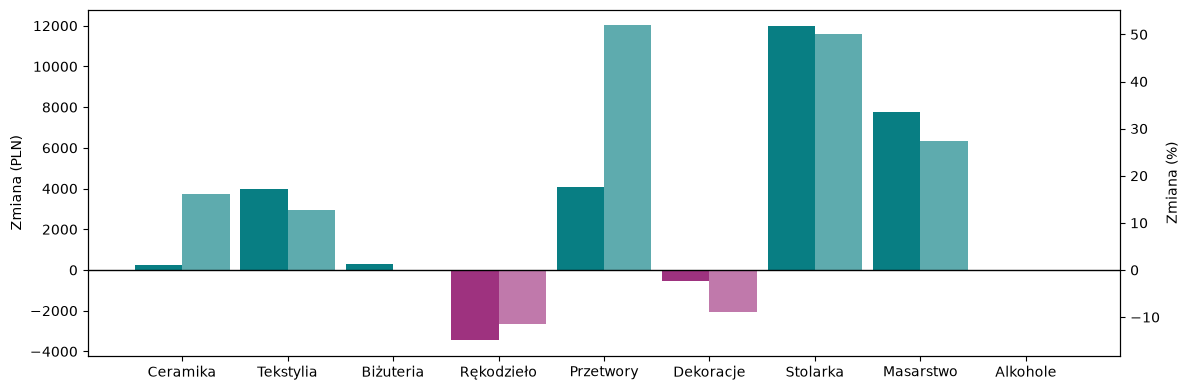

In [55]:
fig = plt.figure(figsize=(12,4))
ax_pln = plt.gca()
ax_pct = ax_pln.twinx()
bars_pln = ax_pln.bar(x_locs-bar_half, t_delta["delta_pln"], width=bar_width, color=colors_pln)
bars_pct = ax_pct.bar(x_locs+bar_half, t_delta["delta_pct_plot"].fillna(0), width=bar_width, color=colors_pct, alpha=0.65)
align_value_expand(ax_pln, 0, ax_pct, 0)
ax_pct.axhline(0, color="black", linewidth=1)
ax_pln.set_xticks(x_locs, order)
ax_pln.set_ylabel("Zmiana (PLN)")
ax_pct.set_ylabel("Zmiana (%)")
plt.tight_layout()
plt.show()

In [56]:
t_delta["delta_pln_plot"] = t_delta["delta_pln"].mask(t_delta["delta_pln"].abs() < 100, 0)

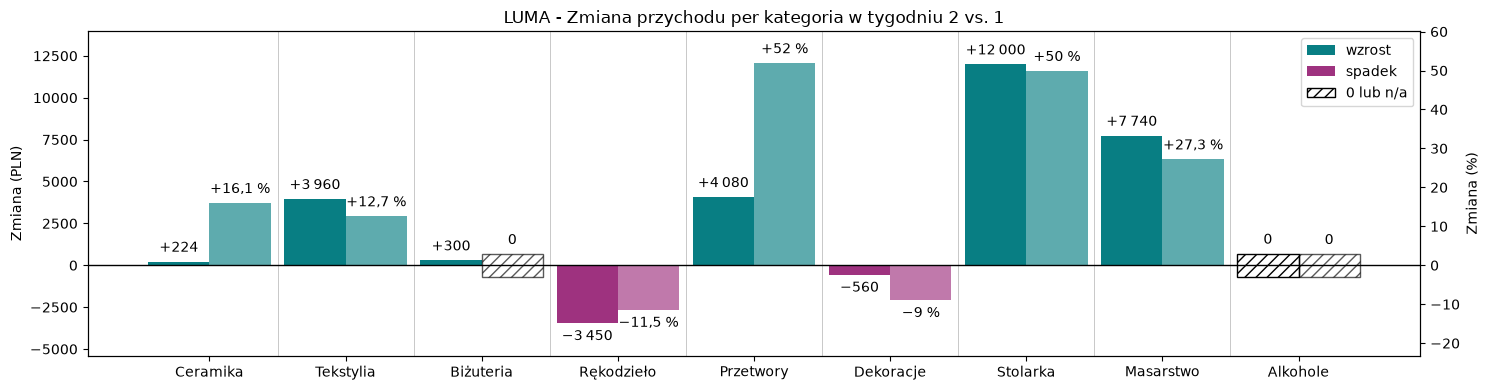

In [57]:
fig = plt.figure(figsize=(15, 4))

ax_pln = plt.gca()
ax_pct = ax_pln.twinx()

bars_pln = ax_pln.bar(x_locs-bar_half, t_delta["delta_pln_plot"], width=bar_width, color=colors_pln)
bars_pct = ax_pct.bar(x_locs+bar_half, t_delta["delta_pct_plot"].fillna(0), width=bar_width, color=colors_pct, alpha=0.65)

modify_zero_bars(bars_pln, t_delta["delta_pln_plot"], y=-700, height=1400, hatch="///", facecolor="none", edgecolor="black")
modify_zero_bars(bars_pct, t_delta["delta_pct_plot"], y=-3, height=6, hatch="///", facecolor="none", edgecolor="black")

pad_ylims(ax_pln)
pad_ylims(ax_pct)

label_bars(ax_pln, bars_pln, t_delta["delta_pln_plot"], formatter=lambda value: format_sep_signed(value) if value else "0")
label_bars(ax_pct, bars_pct, t_delta["delta_pct_plot"], formatter=format_pct_signed)

align_value_expand(ax_pln, 0, ax_pct, 0)

add_manual_legend(
    {"facecolor":increase_color, "label":"wzrost"},
    {"facecolor":decrease_color, "label":"spadek"},
    {"facecolor":"none", "label":"0 lub n/a", "hatch":"///", "edgecolor":"black"}
)
ax_pct.axhline(0, color="black", linewidth=1)
for x in x_locs[:-1] + 0.5:
    ax_pct.axvline(x, color="black", linewidth=0.5, alpha=0.3)
ax_pct.set_xticks(x_locs, order)
ax_pct.set_title("LUMA - Zmiana przychodu per kategoria w tygodniu 2 vs. 1")
ax_pct.set_xlabel("Kategoria")
ax_pct.set_ylabel("Zmiana (%)")
ax_pln.set_ylabel("Zmiana (PLN)")
plt.tight_layout()
plt.show()

In [58]:
t_delta

,category,t1_pln,t2_pln,delta_pln,delta_pct,delta_pct_plot,delta_pln_plot
0,Ceramika,1392,1616,224,16.1,16.1,224
1,Tekstylia,31200,35160,3960,12.7,12.7,3960
2,Biżuteria,38700,39000,300,0.8,0.0,300
3,Rękodzieło,29900,26450,-3450,-11.5,-11.5,-3450
4,Przetwory,7840,11920,4080,52.0,52.0,4080
5,Dekoracje,6195,5635,-560,-9.0,-9.0,-560
6,Stolarka,24000,36000,12000,50.0,50.0,12000
7,Masarstwo,28380,36120,7740,27.3,27.3,7740
8,Alkohole,28620,28620,0,0.0,0.0,0
